## How to Use EvalxNLP Framework for Hate Speech Detection – A Beginner-Friendly Guide 🚀

Hate speech detection is a Natural Language Processing (NLP) task that involves identifying and classifying text that expresses hatred, discrimination, or violence against individuals or groups based on attributes such as race, religion, gender, or sexual orientation.

### Hate Speech Detection:
- **Hate Speech**: Text that explicitly promotes hatred or violence.
- **Offensive Language**: Text that is rude or offensive but does not explicitly promote hatred.
- **Neutral**: Text that does not contain hate speech or offensive language.

In [1]:
import sys
sys.path.append('..')
from XAIbenchmark import XAIFramework
import warnings

warnings.filterwarnings("ignore")

d:\EvalNLP\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%load_ext autoreload
%autoreload 2

#### Single Sentence

Step 1: Load a pre-trained Hate Speech detection Model, and Tokenizer

In [3]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "Hate-speech-CNERG/bert-base-uncased-hatexplain"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Optionally initialize the explainers, and evaluators

In [4]:
import torch
from explainers import InputXGradientExplainer, IntegratedGradientsExplainer, DeepLiftExplainer, LimeExplainer, SHAPExplainer, SHAPIQExplainer, GuidedBackpropExplainer
device = "cuda" if torch.cuda.is_available() else "cpu"
ig= IntegratedGradientsExplainer(model,tokenizer,device)
gb= GuidedBackpropExplainer(model,tokenizer,device)
dl= DeepLiftExplainer(model,tokenizer,device)
ixg= InputXGradientExplainer(model,tokenizer,device,multiply_by_inputs=True)
g= InputXGradientExplainer(model,tokenizer,device,multiply_by_inputs=False)
lime= LimeExplainer(model,tokenizer)
shap= SHAPExplainer(model,tokenizer)
shapiq= SHAPIQExplainer(model,tokenizer)

In [5]:
from evaluators import AUCTPEvaluator, SoftComprehensivenessEvaluator, SoftSufficiencyEvaluator, FADEvaluator, SparsenessEvaluator, ComplexityEvaluator, IOUF1Evaluator,TokenF1Evaluator, AUPRCEvaluator

sc= SoftComprehensivenessEvaluator(model,tokenizer,device)
ss= SoftSufficiencyEvaluator(model,tokenizer,device)
fad= FADEvaluator(model,tokenizer,device)
sp= SparsenessEvaluator(model,tokenizer,device)
cx= ComplexityEvaluator(model,tokenizer,device)
auctp= AUCTPEvaluator(model,tokenizer,device)
iou_f1= IOUF1Evaluator(model,tokenizer,device)
token_f1= TokenF1Evaluator(model,tokenizer,device)
auprc= AUPRCEvaluator(model,tokenizer,device)

Step 3: Inialize XAIBenchmark Class

In [6]:
xai_framework = XAIFramework(model, tokenizer,explainers=[dl,gb,g], evaluators=[auprc,cx],device=device)

> **Note:** If you don’t pass any explainers or evaluators, it defaults to all explainers/evaluators.

Step 4: Detect Hate Speech

In [7]:
sentence= "I hate people from that community"
xai_framework.classify_text(sentence)

BertSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


{'hate speech': 0.06156373396515846,
 'normal': 0.6611422896385193,
 'offensive': 0.27729398012161255}

Step 5: Use EvalxNLP to Explain Why

You can use the `XAIBenchmark` class to explain for all the explainers defined during the initiation of the `XAIBenchmark` class

In [8]:
exps= xai_framework.explain(input_data=sentence,target_label="offensive")

Or you can use an individual explainer's `compute_feature_importance` method to get importance scores.

In [9]:
# ig_exps= ig.compute_feature_importance(sentence, target="offensive")
# gb_exps= gb.compute_feature_importance(sentence, target="offensive")
# dl_exps= dl.compute_feature_importance(sentence, target="offensive")
# ixg_exps= ixg.compute_feature_importance(sentence, target="offensive")
# lime_exps= lime.compute_feature_importance(sentence, target="offensive")
# shap_exps= shap.compute_feature_importance(sentence, target="offensive")
# shapiq_exps= shapiq.compute_feature_importance(sentence, target="offensive")
# g_exps= g.compute_feature_importance(sentence, target="offensive")

Step 5: Visualize the Explanation

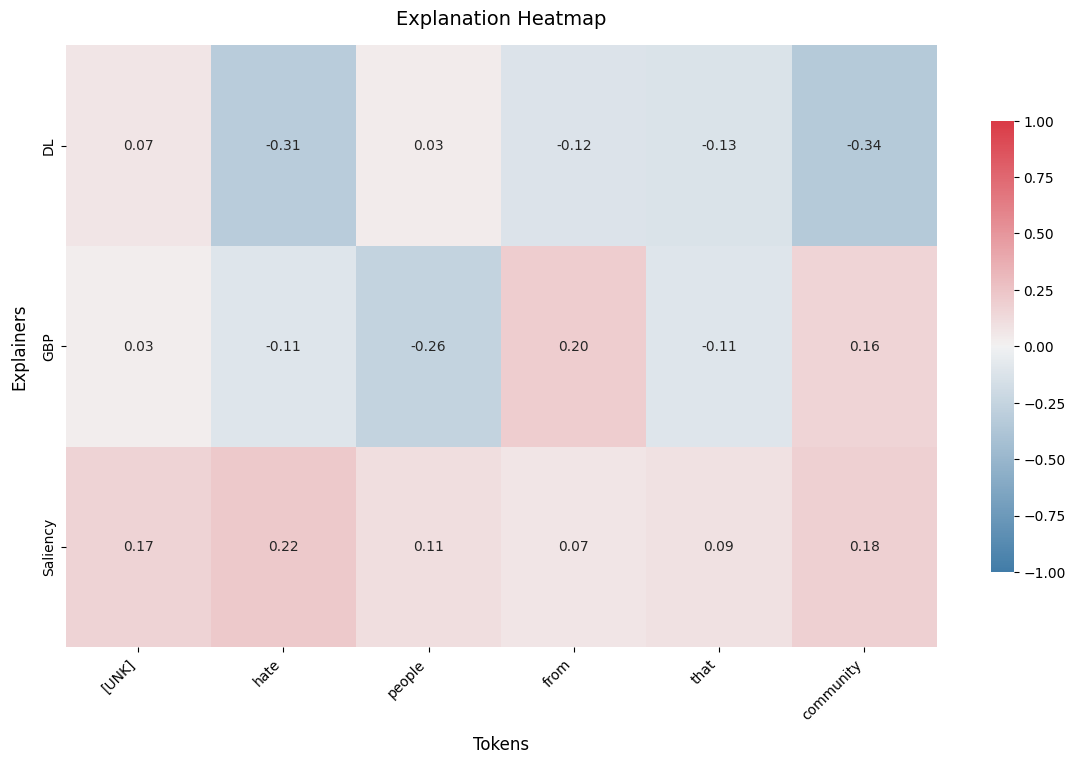

In [10]:
xai_framework.visualize(exps)

Step 5: Evaluate the explanations

You can evaluate explanations from different explainers initialized during the creation of the `XAIBenchmark` class using the `evaluate_single_sentence` function.

- If you provide a **human rationale**, **plausibility metrics** will be calculated.  
- If no rationale is provided, plausibility metrics **will not** be included.  

In [11]:
xai_framework.evaluate_single_sentence(sentence, target_label="offensive")

Skipping AUPRC ↑ as human rationale is not provided.
Skipping AUPRC ↑ as human rationale is not provided.
Skipping AUPRC ↑ as human rationale is not provided.


{'DL': {'Complexity ↓': 0.19228921830654144},
 'GBP': {'Complexity ↓': 0.23476801812648773},
 'Saliency': {'Complexity ↓': 0.24825507402420044}}

Alternatively, you can use each evaluator’s `compute` function to assess individual metrics.  
For **plausibility metrics**, make sure to **add a rationale** to the explanation object before evaluation.

In [12]:
# ig_exps.rationale= [0, 1, 0, 1, 0,0,0,0,1,0,1,0]
# iou_f1.compute(ig_exps)
# auprc.compute(ig_exps)

#### Dataset

Step 1: Load the model and tokenizer

In [13]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "Hate-speech-CNERG/bert-base-uncased-hatexplain"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Load the dataset

You can load any text classification dataset using the `load_fields_from_dataset` function, provided you specify the `LoadDatasetArgs` as follows:  
- **`dataset_name`** - The field containing dataset name on huggingface/ "csv", "json", etc for local files
- **`input_text_field`** – The field containing the text data.  
- **`label_field`** – The field containing the class labels.  
- **`rationale_field`** (optional) – The field marking important tokens in the text.
- **`dataset_files`** (optional) - The field containing filepath to a local csv/excel file e.g. ["healthFC_annotated.csv"]

HuggingFace Dataset

In [14]:
from dataset_loaders.dataset_loader import LoadDatasetArgs,load_fields_from_dataset

dataset_args_ = LoadDatasetArgs(
    dataset_name="Hate-speech-CNERG/hatexplain",
    text_field="post_tokens",
    label_field="annotators",
    rationale_field="rationales",
    dataset_split="test",
)

# Load the dataset fields
results = load_fields_from_dataset(dataset_args_)

Loading dataset...


In [15]:
input_texts= results['text']
labels= results['labels']
rationales= results['rationales']

Expected Outputs:

- **`input_texts`** → An array of strings (text samples).  
- **`labels`** → An array of strings (corresponding class labels).  
- **`rationale`** → An array of binary values (`0` or `1`), indicating which tokens in the text are important.  

*You can preprocess or postprocess the data to ensure it is in the expected format if needed.*

Pre-processing

In [16]:
from dataset_loaders.hatexplain import HateSpeechProcessor

hs= HateSpeechProcessor(tokenizer)
processed_input_texts, processed_labels, processed_rationales= hs.process_dataset(input_texts, labels, rationales)

Select a sub-sample of the dataset

In [17]:
#Select a sub-sample if you want
input_texts_sample=processed_input_texts[300:305]
labels_sample=processed_labels[300:305]
rationale_sample= processed_rationales[300:305]

Step 3: Generate Explanations

In [18]:
exp_scores= xai_framework.get_feature_importance_for_dataset(input_texts_sample,labels_sample,rationale_sample)

Processing instance 0
Computing importance scores for DL
Computing importance scores for GBP
Computing importance scores for Saliency
Processing instance 1
Computing importance scores for DL
Computing importance scores for GBP
Computing importance scores for Saliency
Processing instance 2
Computing importance scores for DL
Computing importance scores for GBP
Computing importance scores for Saliency
Processing instance 3
Computing importance scores for DL
Computing importance scores for GBP
Computing importance scores for Saliency
Processing instance 4
Computing importance scores for DL
Computing importance scores for GBP
Computing importance scores for Saliency


Step 4: Interpret and understand scores by LLM generated textual explanations

In [19]:
from LLMExplanationGenerator import LLMExplanationGenerator
import pandas as pd
from IPython.display import display, HTML

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = LLMExplanationGenerator(api_key=api_key)

# Generate and save explanations (returns both explanations and file paths)
explanations, saved_files = explainer.generate_and_save_explanations(
    exps=exp_scores,
    output_format="both",  # or "json"/"html"
    filename="scores_llm_explanations_moviereviews.html"
)

# Display in notebook
explainer.display_explanations(explanations)

# Print saved locations
print(f"Saved files: {[str(p) for p in saved_files]}")


Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for Saliency scores...
Generating LLM generated textual explanation for Saliency scores...
Generating LLM generated textual explanation for Saliency scores...
Generating LLM generated textual explanation for Saliency scores...
Generating LL

Saved files: ['..\\results\\llm_explanations\\scores_llm_explanations_moviereviews.json', '..\\results\\llm_explanations\\scores_llm_explanations_moviereviews.html']


Step 5: Evaluate Explanations and generate table 

In [20]:
metrics= xai_framework.compute_evaluation_metrics(exp_scores)
xai_framework.create_pivot_table(metrics)


Explainer: DL
Computing value for AUPRC ↑
Computing value for Complexity ↓

Explainer: GBP
Computing value for AUPRC ↑
Computing value for Complexity ↓

Explainer: Saliency
Computing value for AUPRC ↑
Computing value for Complexity ↓


Evaluator,Complexity ↓,AUPRC ↑
Explainer,,
DL,0.097628,0.436478
GBP,0.104584,0.490568
Saliency,0.114075,0.856496


Step 6: Interpret and understand metrics by LLM generated textual explanations

In [21]:
from EvaluationMetricsExplainer import EvaluationMetricsExplainer

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = EvaluationMetricsExplainer(api_key=api_key)

results = explainer.explain_results(metrics)
json_path, html_path = explainer.save_results(results, filename="metrics_llm_explanations_moviereviews")

explainer.display_results(results)

Generating LLM textual explanation for metric: AUPRC ↑
Generating LLM textual explanation for metric: Complexity ↓
LLM generated textual explanations for metrics saved in ..\results\llm_explanations\metrics_llm_explanations_moviereviews.html and ..\results\llm_explanations\metrics_llm_explanations_moviereviews.json


You can also do `Step 3` and `Step 5` together within a single function call.

In [27]:
metrics_result= xai_framework.benchmark_dataset(input_texts_sample, labels_sample)

Processing instance 0
Found cached explanation for DL
Found cached explanation for GBP
Found cached explanation for Saliency
Processing instance 1
Found cached explanation for DL
Found cached explanation for GBP
Found cached explanation for Saliency
Processing instance 2
Found cached explanation for DL
Found cached explanation for GBP
Found cached explanation for Saliency
Processing instance 3
Found cached explanation for DL
Found cached explanation for GBP
Found cached explanation for Saliency
Processing instance 4
Found cached explanation for DL
Found cached explanation for GBP
Found cached explanation for Saliency

Explainer: DL
Computing value for AUPRC ↑
Computing value for Complexity ↓

Explainer: GBP
Computing value for AUPRC ↑
Computing value for Complexity ↓

Explainer: Saliency
Computing value for AUPRC ↑
Computing value for Complexity ↓


In [29]:
xai_framework.create_pivot_table(metrics_result)

Evaluator,Complexity ↓,AUPRC ↑
Explainer,,
DL,0.097628,0.436478
GBP,0.104584,0.490568
Saliency,0.114075,0.856496
